Importções básicas

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

Bibliotecas especializadas

In [3]:
import missingno as msno
from scipy import stats
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer

Configuraões de visualização

In [4]:
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
warnings.filterwarnings('ignore')
os.makedirs('graficos', exist_ok=True)
plt.rcParams['text.parse_math'] = False

print("Bibliotecas importadas com sucesso")

df = pd.read_csv("../credito_aplicacao_clientes_final.csv")

print("Dataset de aplicação de crédito carregado")
print(f"Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas")

Bibliotecas importadas com sucesso
Dataset de aplicação de crédito carregado
Dimensões: 3000 linhas x 19 colunas


Análise estrutural

In [ ]:
# Informções gerais
print(f"Shape: {df.shape}")
print(f"Memória: {df.memory_usage(deep=True).sum()/1024**2:.2f} MB")

# Tipos de dados
print(f"Tipos de dados:\n{df.dtypes}")
print("\n" + "="*40 + "\n")

# Informações detalhadas
print(df.head())

Shape: (3000, 19)
Memória: 2.39 MB
Tipos de dados:
id_cliente                           int64
uf                                  object
municipio                           object
segmento_cliente                    object
natureza_juridica                   object
fonte_cliente                       object
cnae_codigo                         object
capital_social                      object
idade_cnpj                          object
serasa_contagem_negativacoes       float64
serasa_contagem_protestos          float64
serasa_credores                     object
serasa_socio_tem_negativacao       float64
ifood_contagem_avaliacoes           object
ifood_faixa_preco                   object
google_maps_avaliacao               object
google_maps_contagem_avaliacoes     object
google_maps_tem_website            float64
inadimplente                       float64
dtype: object


      id_cliente  uf  municipio segmento_cliente  \
0  1000732585882  CE    CAUCAIA       Segmento 2   
1  100125074

Análise de valores únicos

In [8]:
print("Valores únicos por coluna")
colunas = df.columns.tolist()
valores_unicos = [int(df[col].nunique()) for col in colunas]
percentual_unicos = [(v / len(df)) * 100 for v in valores_unicos]

unique_data = pd.DataFrame({
    'Coluna': colunas,
    'Valores_Unicos': valores_unicos,
    'Percentual_Unicos': percentual_unicos
})

unique_data = unique_data.sort_values('Valores_Unicos', ascending=False)

id_columns = unique_data[unique_data['Valores_Unicos'] == len(df)]['Coluna'].tolist()
if id_columns:
    print(f"A coluna {id_columns} possui valor único (provável chave primária/ID).\n")

print(unique_data.to_string(index=False))
print("\n" + "="*40 + "\n")

Valores únicos por coluna
A coluna ['id_cliente'] possui valor único (provável chave primária/ID).

                         Coluna  Valores_Unicos  Percentual_Unicos
                     id_cliente            3000         100.000000
                serasa_credores             165           5.500000
                    cnae_codigo             153           5.100000
   serasa_contagem_negativacoes              36           1.200000
                      municipio              36           1.200000
               segmento_cliente              21           0.700000
                     idade_cnpj              20           0.666667
                 capital_social              19           0.633333
      serasa_contagem_protestos              18           0.600000
google_maps_contagem_avaliacoes              14           0.466667
      ifood_contagem_avaliacoes              11           0.366667
              natureza_juridica               5           0.166667
                  fonte_clien

Análise de valores ausentes

In [11]:
print("Ausentes por coluna")
missing_data = pd.DataFrame({
    'Coluna': df.columns,
    'Missing_Count': df.isnull().sum(),
    'Missing_Percent': (df.isnull().sum()/len(df)) * 100
})
missing_data = missing_data[missing_data['Missing_Count'] > 0].sort_values('Missing_Percent', ascending=False)

if missing_data.empty:
    print("O dataset nao possui valor faltante")
else:
    print(missing_data.to_string(index=False))
print("\n" + "="*80 + "\n")

Ausentes por coluna
                         Coluna  Missing_Count  Missing_Percent
          google_maps_avaliacao           2966        98.866667
      ifood_contagem_avaliacoes           2814        93.800000
google_maps_contagem_avaliacoes           2792        93.066667
        google_maps_tem_website           2792        93.066667
              ifood_faixa_preco           2637        87.900000
                serasa_credores           2466        82.200000




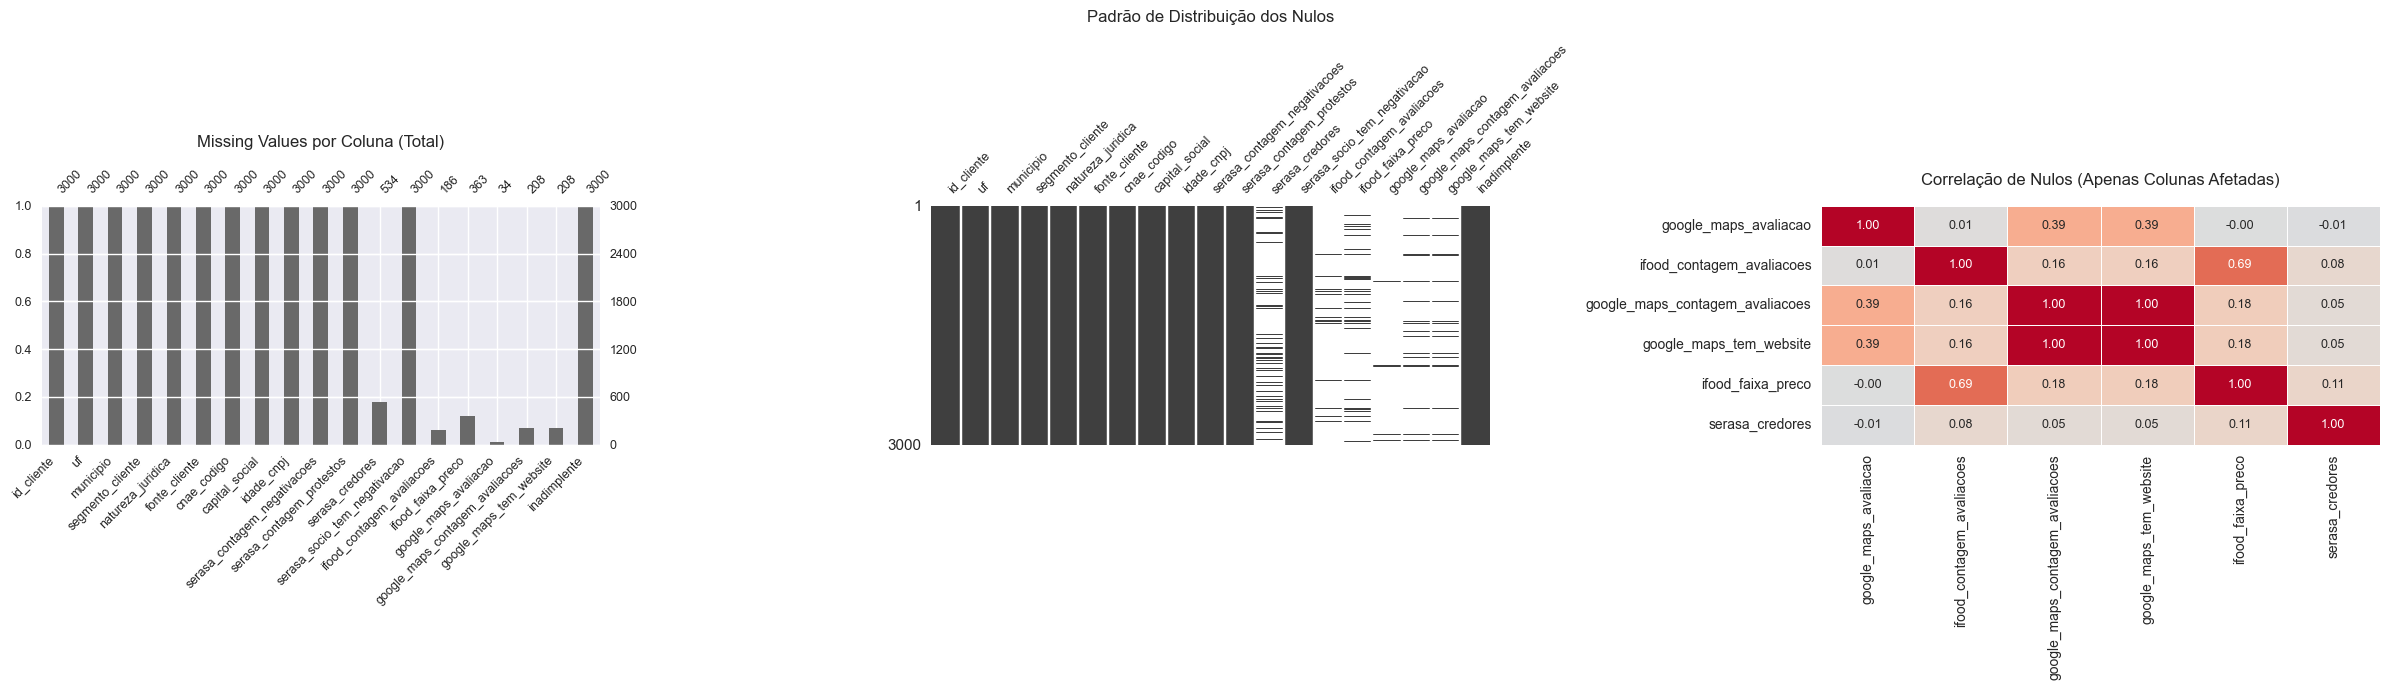

In [12]:
# Gráfico valores ausentes
if not missing_data.empty:
    colunas_com_nulos = missing_data['Coluna'].tolist()
    tem_correlacao_nulos = len(colunas_com_nulos) > 1
    n_graficos = 3 if tem_correlacao_nulos else 2

    fig, axes = plt.subplots(1, n_graficos, figsize=(8 * n_graficos, 7), squeeze=False)
    axes = axes.flatten()

    msno.bar(df, ax=axes[0], fontsize=9)
    axes[0].set_title('Missing Values por Coluna (Total)', fontsize=12, pad=15)

    msno.matrix(df, ax=axes[1], sparkline=False, fontsize=9)
    axes[1].set_title('Padrão de Distribuição dos Nulos', fontsize=12, pad=15)

    if tem_correlacao_nulos:
        missing_corr = df[colunas_com_nulos].isnull().corr()
        sns.heatmap(
            missing_corr, annot=True, fmt=".2f", cmap='coolwarm',
            center=0, ax=axes[2], cbar=False,
            annot_kws={"size": 9}, linewidths=0.5
        )
        axes[2].set_title('Correlação de Nulos (Apenas Colunas Afetadas)', fontsize=12, pad=15)

    plt.tight_layout()
    plt.savefig('graficos/analise_valores_ausentes.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()
else:
    print("Gráficos de valores ausentes não gerados: não há valores faltantes.")

Preparação de variáveis

In [13]:
# 
if 'capital_social' in df.columns:
    df['capital_social'] = (
        df['capital_social']
        .astype('string')
        .str.strip()
        .replace({'': pd.NA, 'nan': pd.NA, 'None': pd.NA})
    )

Conversão de variáveis categóricas em numéricas

In [14]:
var_converter = [
    'serasa_contagem_negativacoes',
    'serasa_contagem_protestos',
    'ifood_contagem_avaliacoes',
    'google_maps_avaliacao',
    'google_maps_contagem_avaliacoes'
]

for var in var_converter:
    if var in df.columns:
        df[var] = pd.to_numeric(df[var], errors='coerce')

In [15]:
if 'idade_cnpj' in df.columns:
    idades = df['idade_cnpj'].astype('string').str.extract(
        r'\(\s*(\d+)\s*,\s*(\d+)\s*\)'
    )

    df['idade_cnpj_coleta_dias'] = pd.to_numeric(
        idades[0], errors='coerce'
    )
    df['idade_cnpj_cadastro_dias'] = pd.to_numeric(
        idades[1], errors='coerce'
    )

df['tempo_cadastro_coleta_dias'] = (
        df['idade_cnpj_coleta_dias'] -
        df['idade_cnpj_cadastro_dias']
    )
df['idade_cnpj_coleta_anos'] = (
        df['idade_cnpj_coleta_dias'] / 365.25
    )
df['idade_cnpj_cadastro_anos'] = (
    df['idade_cnpj_cadastro_dias'] / 365.25
)
df['tempo_cadastro_coleta_anos'] = (
    df['tempo_cadastro_coleta_dias'] / 365.25
)

print("\nVerificação da extração de idade_cnpj:")
print(df[[
    'idade_cnpj_coleta_dias',
    'idade_cnpj_cadastro_dias',
    'tempo_cadastro_coleta_dias'
    ]].describe())
print(
    "Diferenças negativas:",
    (df['tempo_cadastro_coleta_dias'] < 0).sum()
    )

if 'inadimplente' in df.columns:
    df['inadimplente'] = pd.to_numeric(
        df['inadimplente'], errors='coerce'
    )


Verificação da extração de idade_cnpj:
       idade_cnpj_coleta_dias  idade_cnpj_cadastro_dias  \
count                     0.0                       0.0   
mean                      NaN                       NaN   
std                       NaN                       NaN   
min                       NaN                       NaN   
25%                       NaN                       NaN   
50%                       NaN                       NaN   
75%                       NaN                       NaN   
max                       NaN                       NaN   

       tempo_cadastro_coleta_dias  
count                         0.0  
mean                          NaN  
std                           NaN  
min                           NaN  
25%                           NaN  
50%                           NaN  
75%                           NaN  
max                           NaN  
Diferenças negativas: 0


In [16]:
# Variáveis numéricas
numeric_vars = [
    'serasa_contagem_negativacoes',
    'serasa_contagem_protestos',
    'ifood_contagem_avaliacoes',
    'google_maps_avaliacao',
    'google_maps_contagem_avaliacoes',
    'idade_cnpj_coleta_dias',
    'idade_cnpj_cadastro_dias',
    'tempo_cadastro_coleta_dias'
]

In [17]:
# Variáveis categóricas
categorical_vars = [
    'segmento_cliente',
    'natureza_juridica',
    'serasa_credores',
    'uf',
    'fonte_cliente',
    'capital_social',
    'ifood_faixa_preco',
    'google_maps_tem_website',
    'serasa_socio_tem_negativacao'
]

In [20]:
numeric_vars = [v for v in numeric_vars if v in df.columns]
categorical_vars = [v for v in categorical_vars if v in df.columns]

for var in numeric_vars:
    df[var] = pd.to_numeric(df[var], errors='coerce')

numeric_vars_sem_dados = [var for var in numeric_vars if df[var].notna().sum() == 0]
numeric_vars = [var for var in numeric_vars if df[var].notna().sum() > 0]

if numeric_vars_sem_dados:
    print("\nVariáveis numéricas ignoradas por não possuírem valores:", numeric_vars_sem_dados)

Identificação de variáveis categóricas constantes ou nulas

In [21]:
categoricas_constantes = [
    var for var in categorical_vars
    if df[var].nunique(dropna=True) <= 1
]
categoricas_variaveis = [
    var for var in categorical_vars
    if df[var].nunique(dropna=True) > 1
]

In [22]:
# Ordenar capital_social pelo limite inferior
def chave_faixa_capital(faixa):
    import re
    correspondencia = re.search(
        r"\(\s*(-?\d+(?:[.,]\d+)?)\s*,",
        str(faixa)
    )
    if correspondencia:
        return float(correspondencia.group(1).replace(',', '.'))
    return float('inf')

print("\nVariáveis numéricas:", numeric_vars)
print("Variáveis categóricas:", categorical_vars)
print("Categóricas constantes/sem variação:", categoricas_constantes)
print("Categóricas usadas nos gráficos:", categoricas_variaveis)

for var in ['uf', 'google_maps_tem_website']:
    if var in df.columns:
        print(f"\nValores de {var}:")
        print(df[var].value_counts(dropna=False))


Variáveis numéricas: ['serasa_contagem_negativacoes', 'serasa_contagem_protestos']
Variáveis categóricas: ['segmento_cliente', 'natureza_juridica', 'serasa_credores', 'uf', 'fonte_cliente', 'capital_social', 'ifood_faixa_preco', 'google_maps_tem_website', 'serasa_socio_tem_negativacao']
Categóricas constantes/sem variação: ['uf', 'google_maps_tem_website']
Categóricas usadas nos gráficos: ['segmento_cliente', 'natureza_juridica', 'serasa_credores', 'fonte_cliente', 'capital_social', 'ifood_faixa_preco', 'serasa_socio_tem_negativacao']

Valores de uf:
CE    3000
Name: uf, dtype: int64

Valores de google_maps_tem_website:
NaN    2792
1.0     208
Name: google_maps_tem_website, dtype: int64


Análise univariada variáveis numéricas

In [23]:
for var in numeric_vars:
    data = df[var].dropna()

    print(f"\n📊 {var.upper()}")

    if len(data) == 0:
        print("Não existem valores disponíveis.")
        continue

    print(f"Média: {data.mean():.2f}")
    print(f"Mediana: {data.median():.2f}")
    print(f"Desvio padrão: {data.std():.2f}")
    print(f"Valores únicos: {data.nunique()}")

    if data.nunique() > 1:
        print(f"Assimetria: {stats.skew(data):.2f}")
        print(f"Curtose: {stats.kurtosis(data):.2f}")

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    outliers = data[
        (data < Q1 - 1.5 * IQR) |
        (data > Q3 + 1.5 * IQR)
    ]

    print(f"Outliers: {len(outliers)}")


📊 SERASA_CONTAGEM_NEGATIVACOES
Média: 1.00
Mediana: 0.00
Desvio padrão: 4.46
Valores únicos: 36
Assimetria: 14.98
Curtose: 365.76
Outliers: 631

📊 SERASA_CONTAGEM_PROTESTOS
Média: 0.26
Mediana: 0.00
Desvio padrão: 1.94
Valores únicos: 18
Assimetria: 25.41
Curtose: 936.62
Outliers: 231


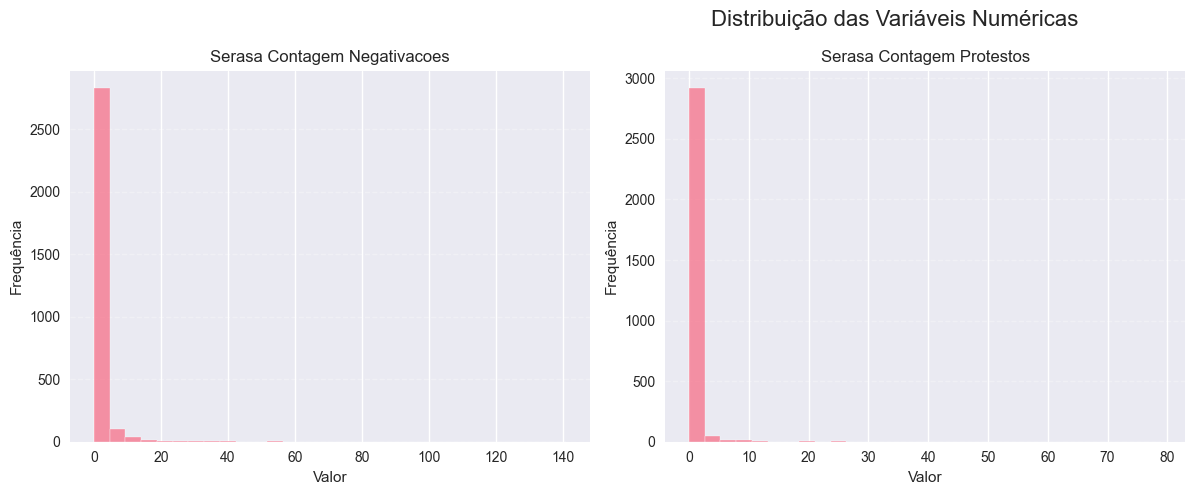

In [24]:
# Histograma
if numeric_vars:
    n_cols = 3
    n_rows = int(np.ceil(len(numeric_vars) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows), squeeze=False)
    fig.suptitle('Distribuição das Variáveis Numéricas', fontsize=16)

    for i, var in enumerate(numeric_vars):
        ax = axes.flatten()[i]
        data = df[var].dropna()
        if data.empty:
            fig.delaxes(ax)
            continue
        ax.hist(data, bins=30, alpha=0.75, edgecolor='white')
        ax.set_title(var.replace('_', ' ').title())
        ax.set_ylabel('Frequência')
        ax.set_xlabel('Valor')
        ax.grid(axis='y', linestyle='--', alpha=0.3)

    for j in range(len(numeric_vars), n_rows * n_cols):
        fig.delaxes(axes.flatten()[j])

    plt.tight_layout()
    plt.savefig('graficos/distribuicao_numericas.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()
else:
    print("Histograma não gerado: nenhuma variável numérica possui valores.")

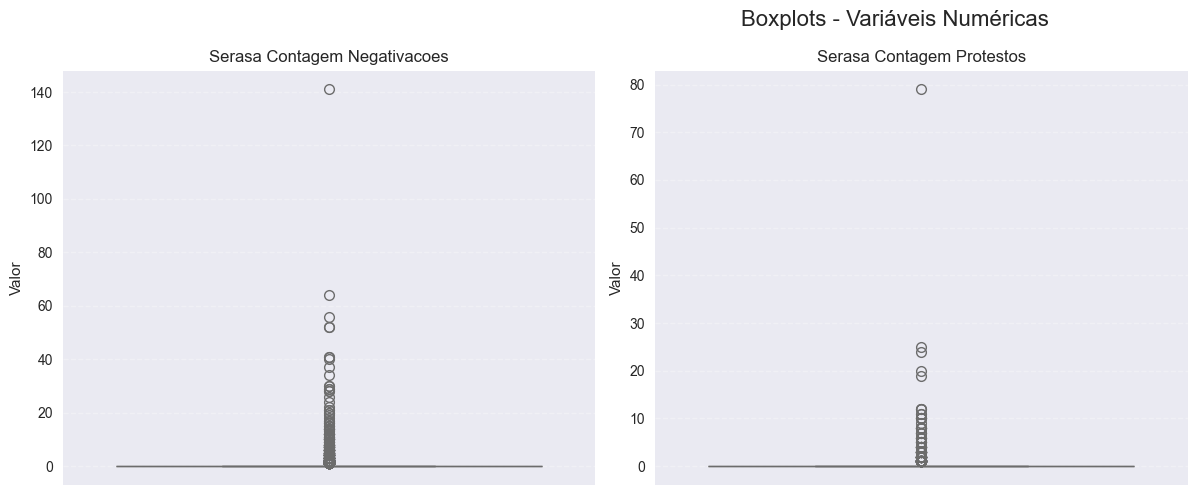

In [25]:
# Boxplot
if numeric_vars:
    n_cols = 3
    n_rows = int(np.ceil(len(numeric_vars) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows), squeeze=False)
    fig.suptitle('Boxplots - Variáveis Numéricas', fontsize=16)

    for i, var in enumerate(numeric_vars):
        ax = axes.flatten()[i]
        data = df[var].dropna()
        if data.empty:
            fig.delaxes(ax)
            continue
        sns.boxplot(y=data, ax=ax, color=sns.color_palette("husl", 1)[0])
        ax.set_title(var.replace('_', ' ').title())
        ax.set_ylabel('Valor')
        ax.grid(axis='y', linestyle='--', alpha=0.3)

    for j in range(len(numeric_vars), n_rows * n_cols):
        fig.delaxes(axes.flatten()[j])

    plt.tight_layout()
    plt.savefig('graficos/boxplots_numericas.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()
else:
    print("Boxplots não gerados: nenhuma variável numérica possui valores.")

Análise univariada variáveis categóricas

In [26]:
for var in categorical_vars:
    print(f"\n📊 {var.upper()}")

    freq = df[var].value_counts(dropna=False)
    print(freq.head(10))

    print("\nPercentual:")
    print((df[var].value_counts(normalize=True) * 100).head(10))


📊 SEGMENTO_CLIENTE
Segmento 16    613
Segmento 20    609
Segmento 15    343
Segmento 18    300
Segmento 10    211
Segmento 19    210
Segmento 5     162
Segmento 9      94
Segmento 3      88
Segmento 17     71
Name: segmento_cliente, dtype: int64

Percentual:
Segmento 16    20.433333
Segmento 20    20.300000
Segmento 15    11.433333
Segmento 18    10.000000
Segmento 10     7.033333
Segmento 19     7.000000
Segmento 5      5.400000
Segmento 9      3.133333
Segmento 3      2.933333
Segmento 17     2.366667
Name: segmento_cliente, dtype: float64

📊 NATUREZA_JURIDICA
213-5 - Empresário (Individual)                                                     2249
206-2 - Sociedade Empresária Limitada                                                736
230-5 - Empresa Individual de Responsabilidade Limitada (de Natureza Empresária)      12
224-0 - Sociedade Simples Limitada                                                     2
205-4 - Sociedade Anônima Fechada                                         

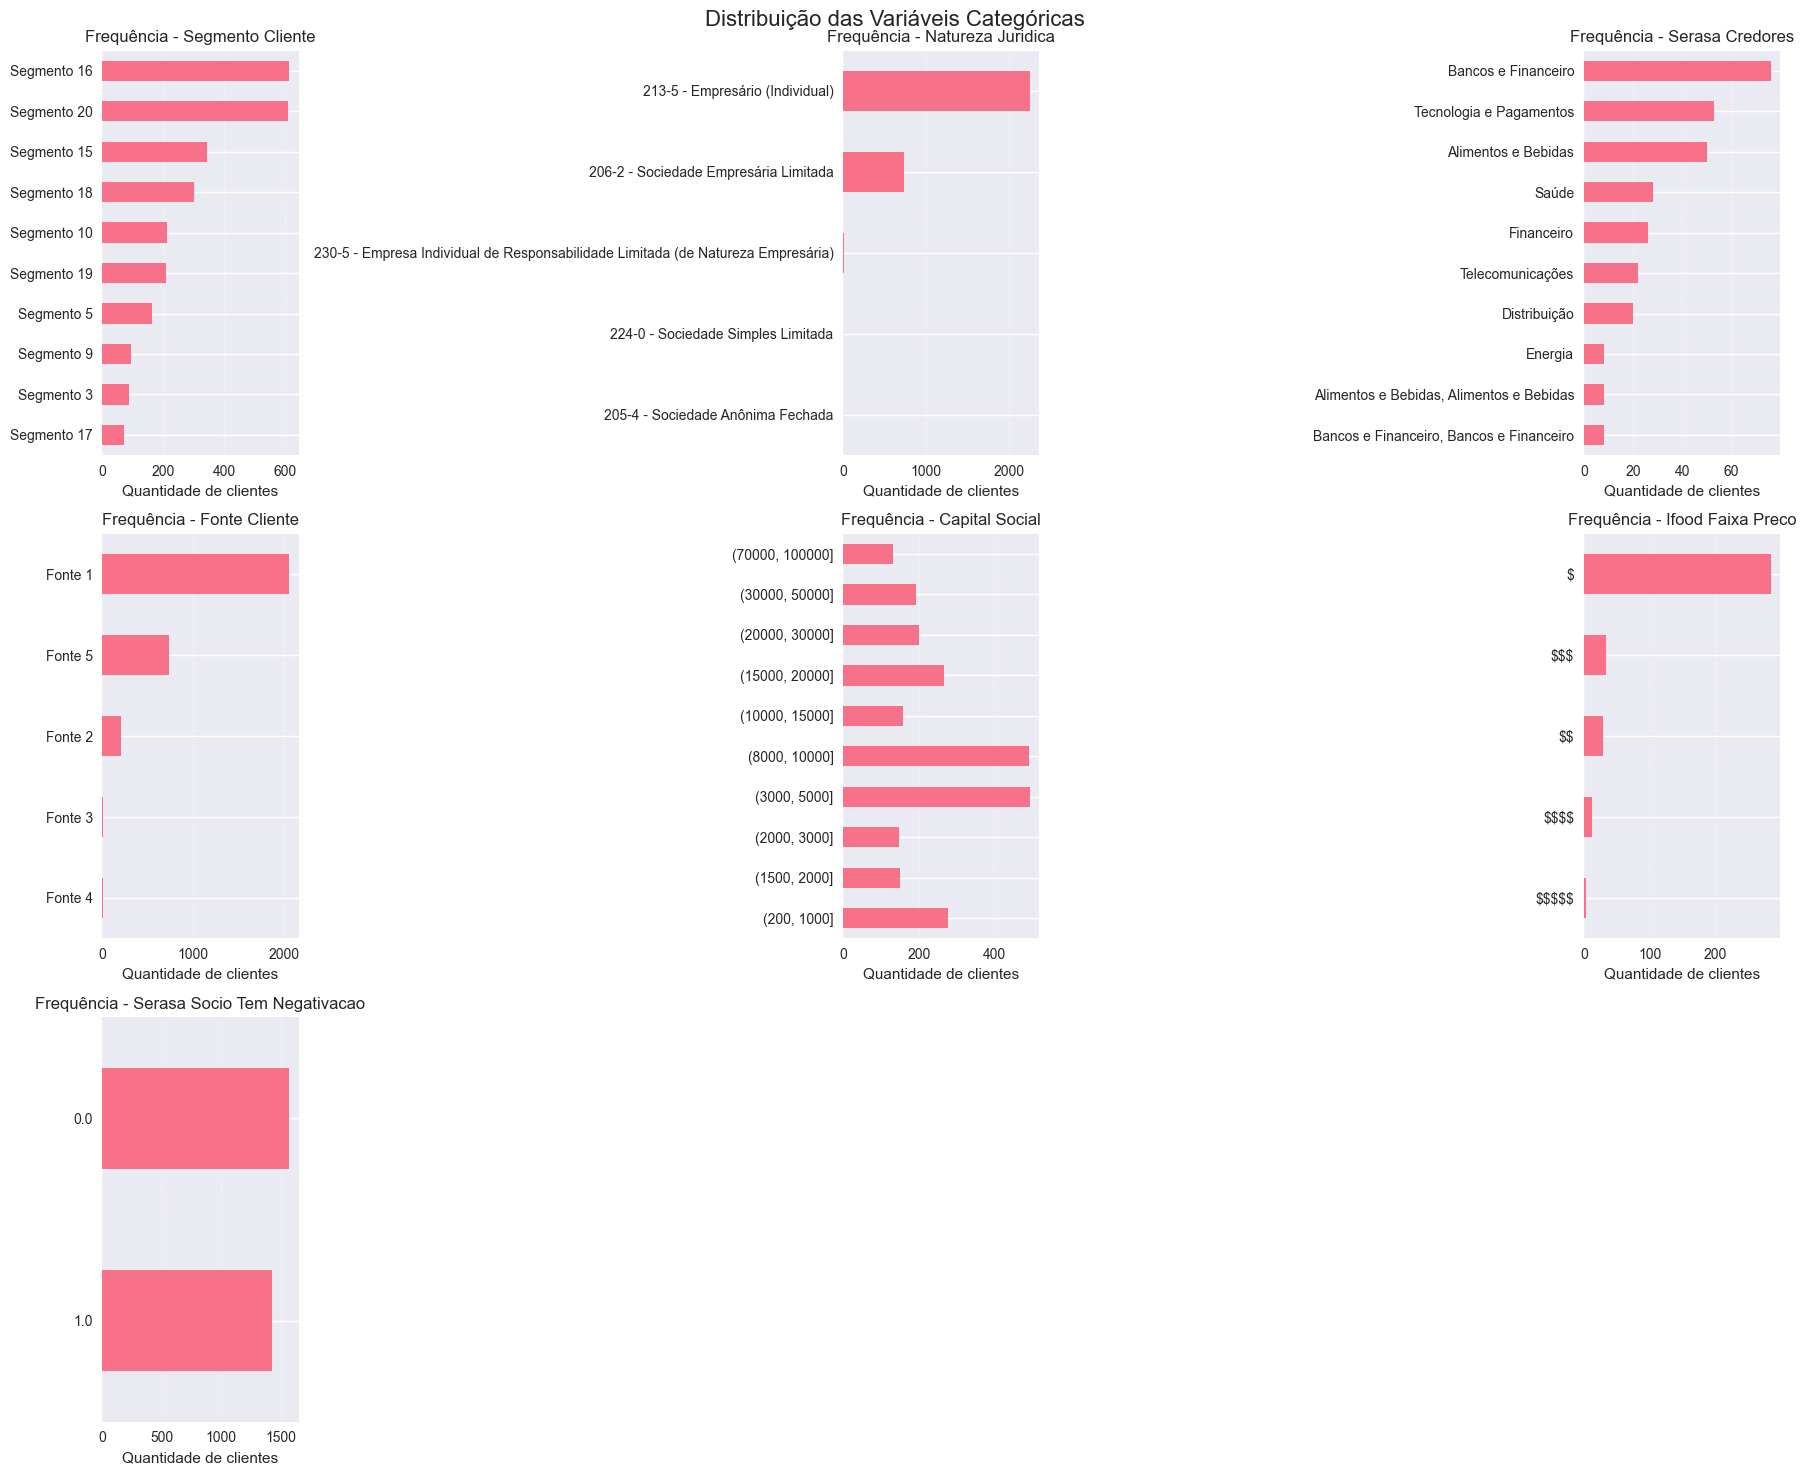

In [27]:
# Gráficos
categoricas_com_dados = [var for var in categoricas_variaveis if df[var].notna().any()]

if categoricas_com_dados:
    n_cols_cat = 3
    n_rows_cat = int(np.ceil(len(categoricas_com_dados) / n_cols_cat))
    fig, axes = plt.subplots(n_rows_cat, n_cols_cat, figsize=(18, 5 * n_rows_cat), squeeze=False)
    fig.suptitle('Distribuição das Variáveis Categóricas', fontsize=16)

    for i, var in enumerate(categoricas_com_dados):
        ax = axes.flatten()[i]
        value_counts = df[var].dropna().value_counts().head(10)
        if value_counts.empty:
            fig.delaxes(ax)
            continue
        if var == 'capital_social':
            value_counts = value_counts.reindex(sorted(value_counts.index, key=chave_faixa_capital))
        else:
            value_counts = value_counts.sort_values()

        value_counts.plot(kind='barh', ax=ax)
        ax.set_title(f'Frequência - {var.replace("_", " ").title()}')
        ax.set_xlabel('Quantidade de clientes')
        ax.set_ylabel('')
        ax.grid(axis='x', linestyle='--', alpha=0.3)
        ax.set_axisbelow(True)

    for j in range(len(categoricas_com_dados), n_rows_cat * n_cols_cat):
        fig.delaxes(axes.flatten()[j])

    plt.tight_layout()
    plt.savefig('graficos/distribuicao_categoricas.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()
else:
    print("Gráficos categóricos não gerados: nenhuma variável possui valores.")

Distribuição de inadimplência


Distribuição da inadimplência:
0.0    2060
1.0     940
Name: inadimplente, dtype: int64

Percentual:
0.0    68.666667
1.0    31.333333
Name: inadimplente, dtype: float64


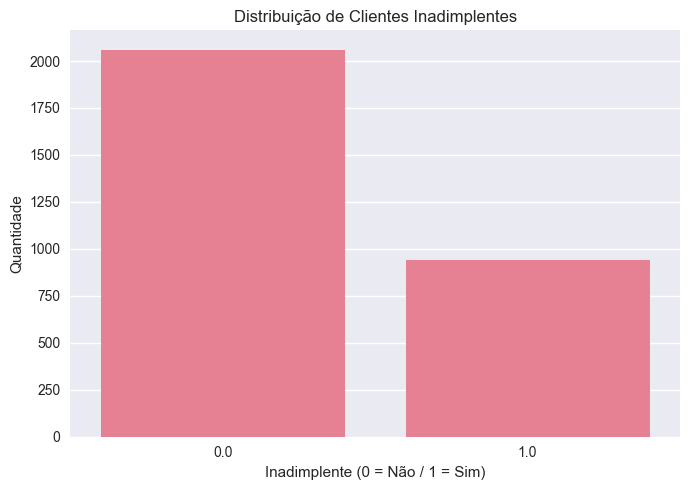

In [29]:
if 'inadimplente' in df.columns:
    alvo_valido = pd.to_numeric(df['inadimplente'], errors='coerce').dropna()
    if not alvo_valido.empty:
        print("\nDistribuição da inadimplência:")
        print(alvo_valido.value_counts())
        print("\nPercentual:")
        print(alvo_valido.value_counts(normalize=True) * 100)

        plt.figure(figsize=(7, 5))
        sns.countplot(x=alvo_valido)
        plt.title('Distribuição de Clientes Inadimplentes')
        plt.xlabel('Inadimplente (0 = Não / 1 = Sim)')
        plt.ylabel('Quantidade')
        plt.tight_layout()
        plt.savefig('graficos/distribuicao_inadimplencia.png', dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()
    else:
        print("Gráfico de inadimplência não gerado: não há valores disponíveis.")
else:
    print("Gráfico de inadimplência não gerado: coluna 'inadimplente' inexistente.")

Numéricas X Inadimplência

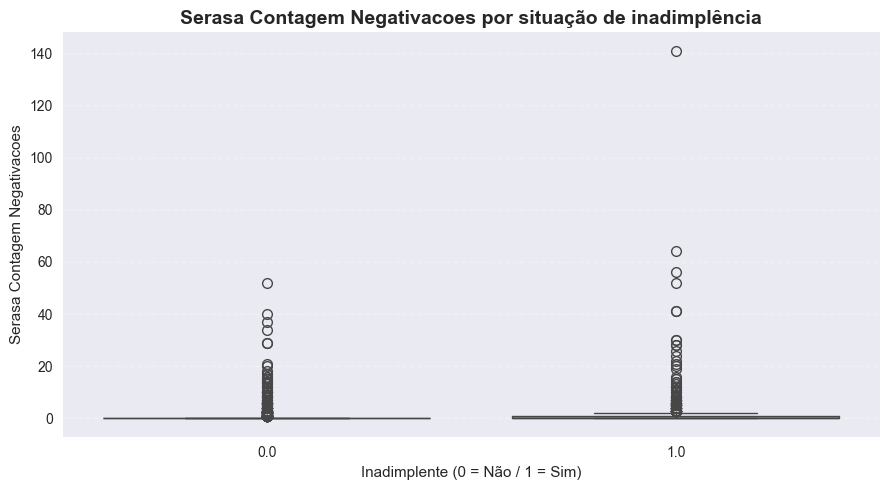

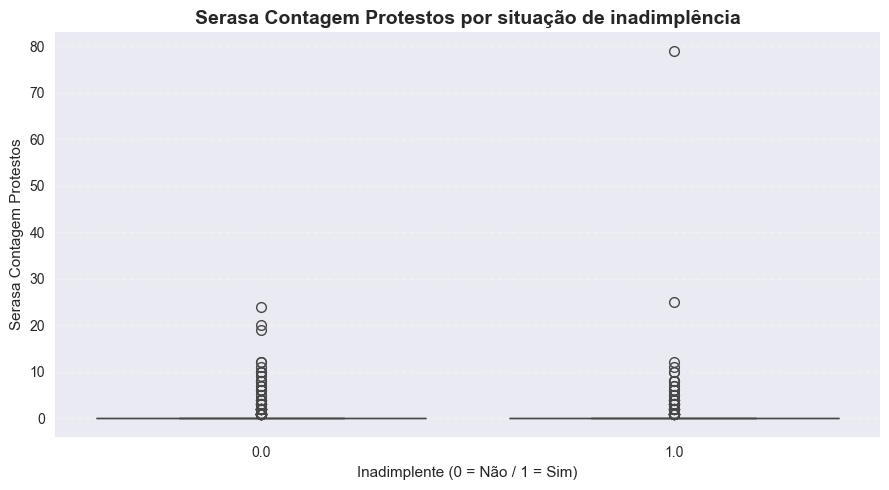

In [30]:
for var in numeric_vars:
    # cópia apenas com as colunas necessárias
    dados = df[['inadimplente', var]].copy()

    # converte as colunas para numérico
    dados['inadimplente'] = pd.to_numeric(
        dados['inadimplente'], errors='coerce'
    )

    dados[var] = pd.to_numeric(
        dados[var], errors='coerce'
    )

    # remove valores ausentes
    dados = dados.dropna()

    # verifica se existem dados para os dois grupos
    if dados.empty or dados['inadimplente'].nunique() < 2:
        print(f"Pulando {var}: dados insuficientes.")
        continue

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=dados,
        x='inadimplente',
        y=var,
        hue='inadimplente',
        palette={0: '#4C9F70', 1: '#E76F51'},
        legend=False
    )

    plt.title(
        f'{var.replace("_", " ").title()} por situação de inadimplência',
        fontsize=14,
        fontweight='bold'
    )

    plt.xlabel('Inadimplente (0 = Não / 1 = Sim)')
    plt.ylabel(var.replace('_', ' ').title())

    plt.grid(axis='y', linestyle='--', alpha=0.3)
    sns.despine()

    plt.tight_layout()

    nome_arquivo = var.replace('/', '_')

    plt.savefig(
        f'graficos/bivariada_{nome_arquivo}.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()
    plt.close()

Categóricas X Inadimplência


Taxa de inadimplência por segmento_cliente:
                  taxa_inadimplencia  quantidade
segmento_cliente                                
Segmento 18                19.000000         300
Segmento 5                 21.604938         162
Segmento 16                23.980424         613
Segmento 15                30.903790         343
Segmento 17                35.211268          71
Segmento 20                35.303777         609
Segmento 10                38.388626         211
Segmento 19                44.285714         210
Segmento 9                 44.680851          94
Segmento 3                 47.727273          88


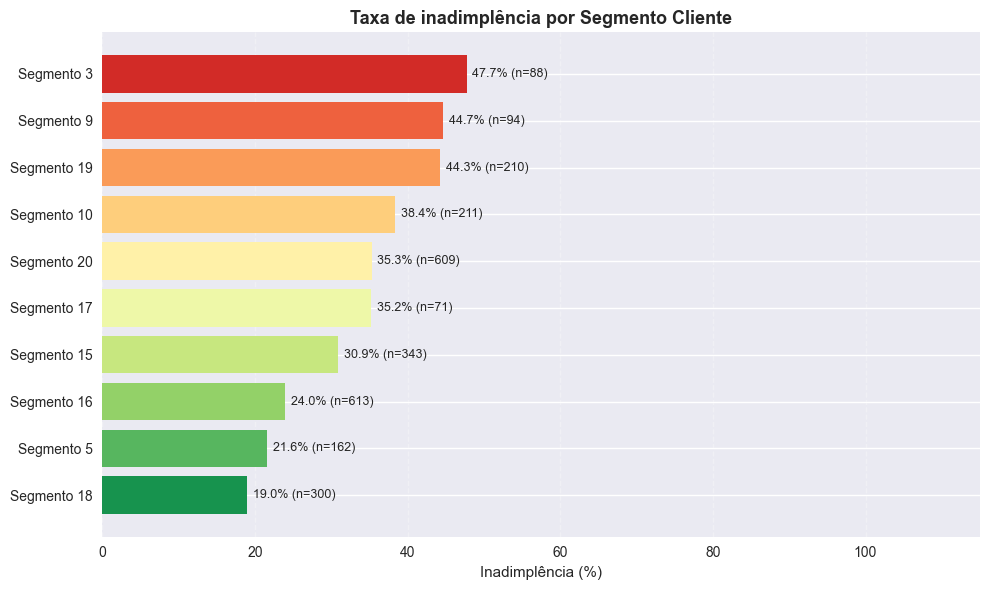


Taxa de inadimplência por natureza_juridica:
                                                    taxa_inadimplencia  \
natureza_juridica                                                        
224-0 - Sociedade Simples Limitada                            0.000000   
230-5 - Empresa Individual de Responsabilidade ...            8.333333   
206-2 - Sociedade Empresária Limitada                        21.331522   
213-5 - Empresário (Individual)                              34.726545   
205-4 - Sociedade Anônima Fechada                           100.000000   

                                                    quantidade  
natureza_juridica                                               
224-0 - Sociedade Simples Limitada                           2  
230-5 - Empresa Individual de Responsabilidade ...          12  
206-2 - Sociedade Empresária Limitada                      736  
213-5 - Empresário (Individual)                           2249  
205-4 - Sociedade Anônima Fechada            

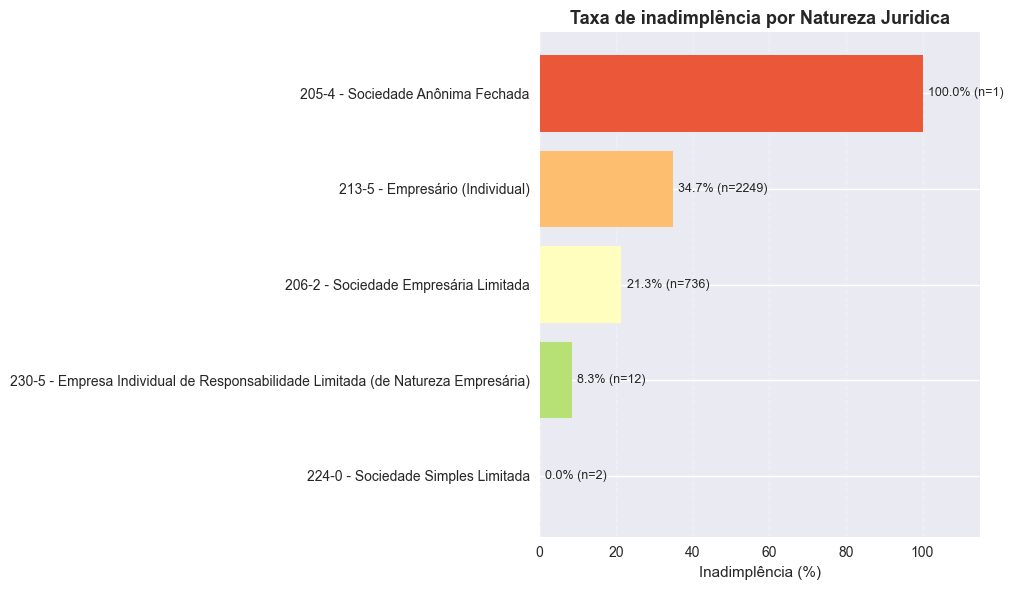


Taxa de inadimplência por serasa_credores:
                                          taxa_inadimplencia  quantidade
serasa_credores                                                         
Energia                                             0.000000           8
Telecomunicações                                   22.727273          22
Não informado                                      27.615572        2466
Tecnologia e Pagamentos                            30.188679          53
Saúde                                              32.142857          28
Distribuição                                       40.000000          20
Financeiro                                         42.307692          26
Bancos e Financeiro                                48.684211          76
Alimentos e Bebidas                                50.000000          50
Bancos e Financeiro, Bancos e Financeiro           62.500000           8


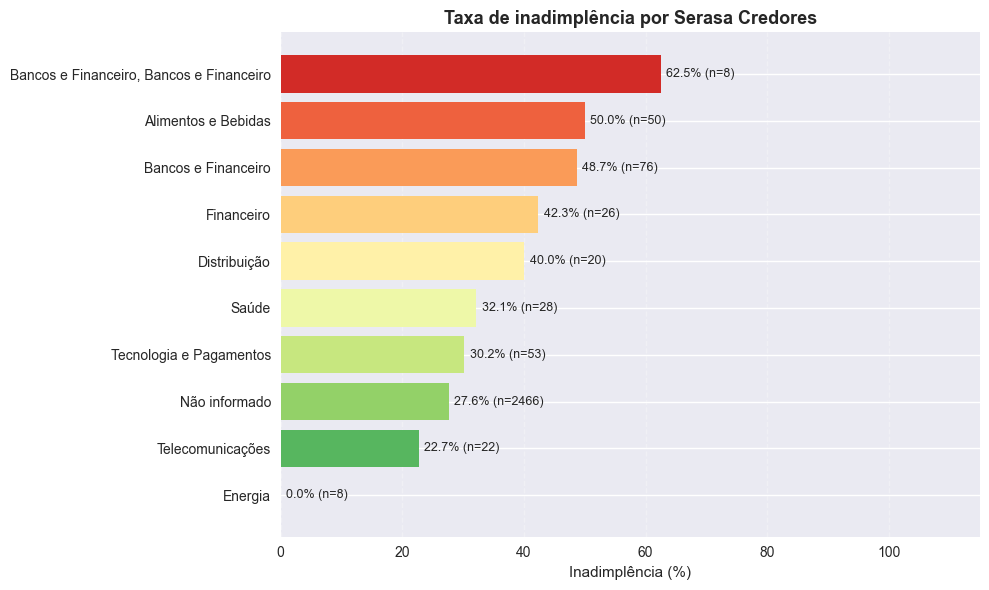


Taxa de inadimplência por fonte_cliente:
               taxa_inadimplencia  quantidade
fonte_cliente                                
Fonte 1                 27.250608        2055
Fonte 3                 28.571429           7
Fonte 5                 37.500000         736
Fonte 4                 50.000000           2
Fonte 2                 50.500000         200


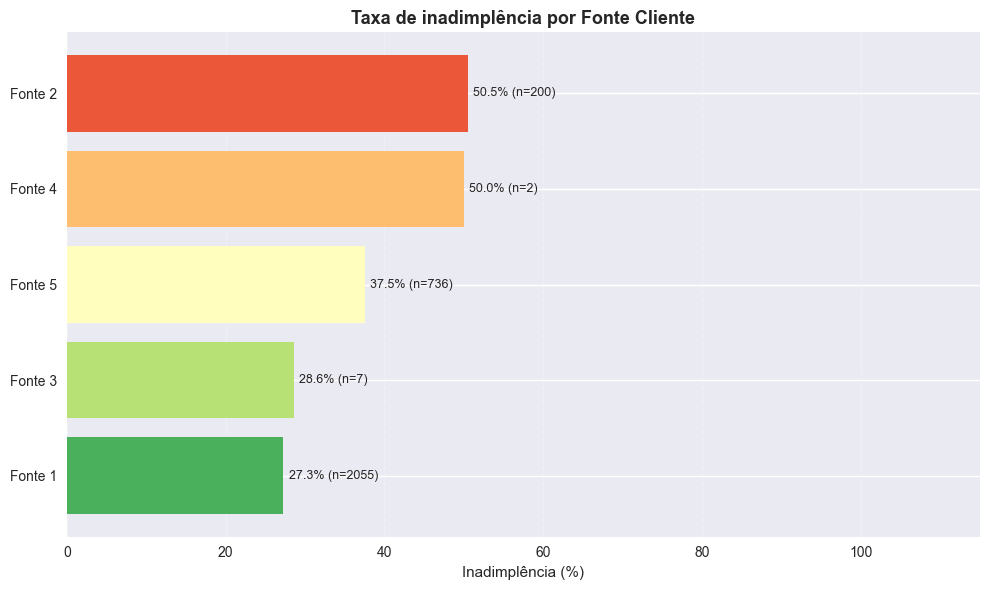


Taxa de inadimplência por capital_social:
                 taxa_inadimplencia  quantidade
capital_social                                 
(200, 1000]               40.942029         276
(1500, 2000]              36.000000         150
(2000, 3000]              37.414966         147
(3000, 5000]              31.578947         494
(8000, 10000]             26.476578         491
(10000, 15000]            26.582278         158
(15000, 20000]            28.571429         266
(20000, 30000]            26.865672         201
(30000, 50000]            30.051813         193
(70000, 100000]           20.610687         131


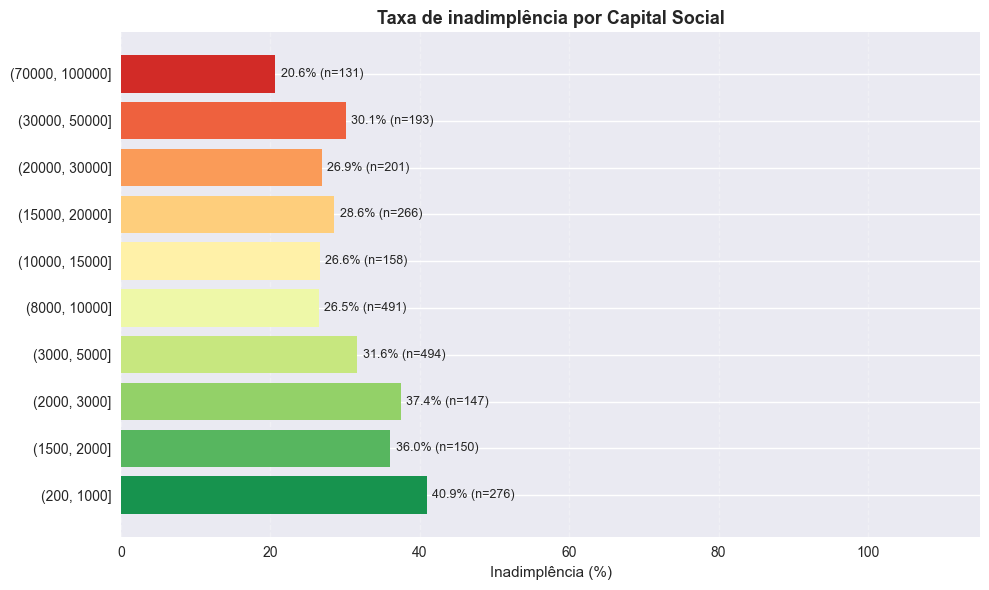


Taxa de inadimplência por ifood_faixa_preco:
                   taxa_inadimplencia  quantidade
ifood_faixa_preco                                
$$$$$                        0.000000           3
$$                          17.241379          29
$                           26.408451         284
Não informado               31.968146        2637
$$$                         32.352941          34
$$$$                        46.153846          13


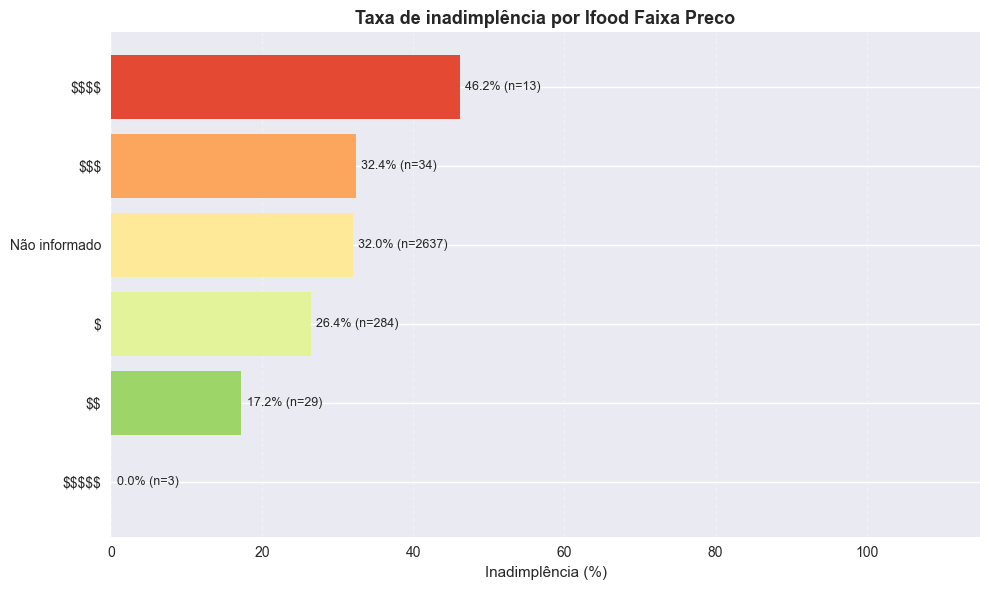


Taxa de inadimplência por serasa_socio_tem_negativacao:
                              taxa_inadimplencia  quantidade
serasa_socio_tem_negativacao                                
0.0                                    22.123331        1573
1.0                                    41.485634        1427


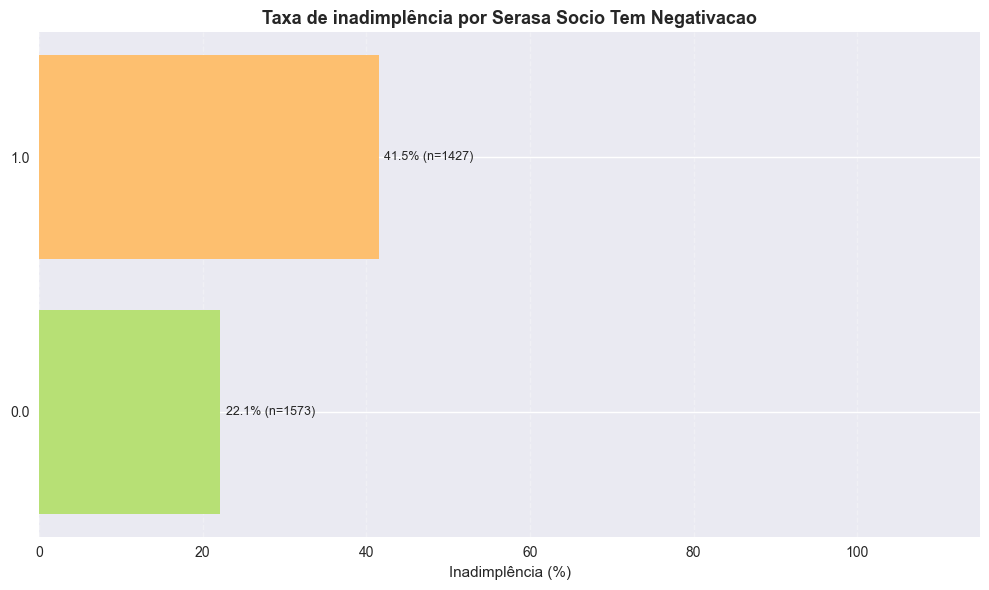

In [31]:
for var in categoricas_variaveis:
    dados = df[[var, 'inadimplente']].copy()
    dados['inadimplente'] = pd.to_numeric(
        dados['inadimplente'], errors='coerce'
    )
    dados = dados.dropna(subset=['inadimplente'])
    dados[var] = dados[var].fillna('Não informado')

    # apenas as 10 categorias mais frequentes
    categorias_principais = (
        dados[var].value_counts().head(10).index
    )
    dados = dados[dados[var].isin(categorias_principais)]

    resultado = (
        dados.groupby(var, observed=False)
        .agg(
            taxa_inadimplencia=('inadimplente', 'mean'),
            quantidade=('inadimplente', 'size')
        )
    )
    resultado['taxa_inadimplencia'] *= 100

    if var == 'capital_social':
        resultado = resultado.reindex(
            sorted(resultado.index, key=chave_faixa_capital)
        )
    else:
        resultado = resultado.sort_values('taxa_inadimplencia')

    print(f"\nTaxa de inadimplência por {var}:")
    print(resultado)

    if resultado.empty:
        print(f"Pulando {var}: não há dados válidos para calcular a taxa de inadimplência.")
        continue

    fig, ax = plt.subplots(figsize=(10, 6))
    barras = ax.barh(
        resultado.index.astype(str),
        resultado['taxa_inadimplencia'],
        color=sns.color_palette("RdYlGn_r", len(resultado))
    )

    rotulos = [
        f"{taxa:.1f}% (n={n})"
        for taxa, n in zip(
            resultado['taxa_inadimplencia'],
            resultado['quantidade']
        )
    ]
    ax.bar_label(barras, labels=rotulos, padding=4, fontsize=9)
    ax.set_title(
        f'Taxa de inadimplência por {var.replace("_", " ").title()}',
        fontsize=13,
        fontweight='bold'
    )
    ax.set_xlabel('Inadimplência (%)')
    ax.set_ylabel('')
    ax.set_xlim(0, 115)
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)
    sns.despine()
    plt.tight_layout()

    nome_arquivo = var.replace('/', '_')
    plt.savefig(
        f'graficos/bivariada_{nome_arquivo}.png',
        dpi=300,
        bbox_inches='tight'
    )
    plt.show()
    plt.close()


Matriz de Correlação

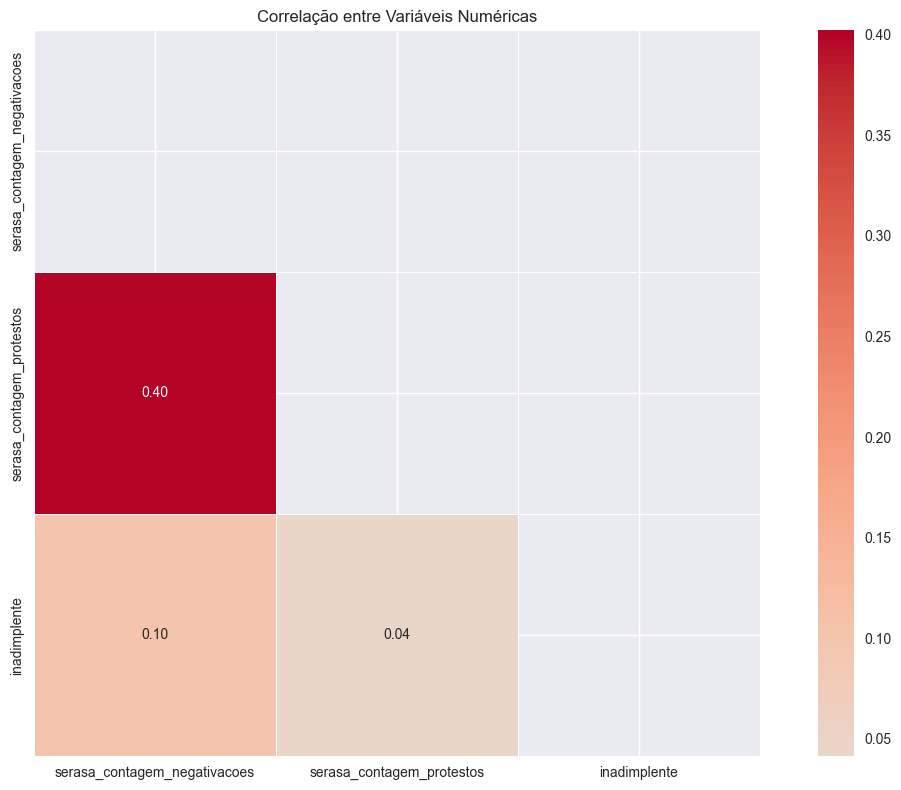


Análise exploratória concluída!


In [32]:
colunas_correlacao = [
    var for var in numeric_vars + ['inadimplente']
    if var in df.columns
    and pd.to_numeric(df[var], errors='coerce').notna().sum() > 0
    and pd.to_numeric(df[var], errors='coerce').nunique() > 1
]

if len(colunas_correlacao) >= 2:
    corr = df[colunas_correlacao].apply(pd.to_numeric, errors='coerce').corr()
    corr = corr.dropna(axis=0, how='all').dropna(axis=1, how='all')

    if corr.shape[0] >= 2:
        plt.figure(figsize=(12, 8))
        mask = np.triu(np.ones_like(corr, dtype=bool))
        sns.heatmap(
            corr, mask=mask, annot=True, cmap='coolwarm',
            fmt='.2f', center=0, square=True, linewidths=0.5
        )
        plt.title('Correlação entre Variáveis Numéricas')
        plt.tight_layout()
        plt.savefig('graficos/matriz_correlacao.png', dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()
    else:
        print("Matriz de correlação não gerada: correlações válidas insuficientes.")
else:
    print("Matriz de correlação não gerada: são necessárias pelo menos duas variáveis numéricas com variação.")

print("\nAnálise exploratória concluída!")